**NOM: REGUI YASSINE**  -  MASTER IAA


importing librarys

In [97]:
import numpy as np
import pandas as pd


**Partie 1 : Introduction au Dataset**

chargez le dataset titanic

In [98]:
titanic = pd.read_csv("/TP_1/titanic.csv")

In [99]:
print(titanic.shape)

(891, 12)


Identifiez les types de données

In [100]:
print(titanic.dtypes)

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


Visualisez les premières lignes du dataset.

In [101]:
print(titanic.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  


Vérifiez les valeurs manquantes

In [102]:
print(titanic.isnull().sum())


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


**Partie 2 : Nettoyage des Données**

séparée les données de test et de train ( survived )

In [103]:
from sklearn.model_selection import train_test_split

In [104]:
y = titanic['Survived']
x = titanic.drop(columns=['Survived'])
x_train, x_test, y_train, y_test = train_test_split(x , y , test_size= 0.2 , random_state=42 )
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(712, 11)
(179, 11)
(712,)
(179,)


**1. Gestion des valeurs manquantes :**

les colonnes avec des valeurs manquantes.

In [105]:
print(titanic.columns[titanic.isnull().any()])

Index(['Age', 'Cabin', 'Embarked'], dtype='object')


Pour les variables numériques [Age], on remplace les valeurs manquantes par
la moyenne

In [106]:

age_mean = x_train['Age'].mean()
x_train['Age'] = x_train['Age'].fillna(age_mean)
x_test['Age'] = x_test['Age'].fillna(age_mean)

In [107]:
print(x_train.isnull().sum())

PassengerId      0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          553
Embarked         2
dtype: int64


Pour les variables catégorielles, remplacez les valeurs manquantes par
la mode ET (plus de 40 %), vous
pouvez envisager de la supprimer.

In [108]:
porcentage_ob = x_train.isnull().mean() * 100
print(porcentage_ob)
x_train = x_train.drop(columns= porcentage_ob[porcentage_ob>40].index)
x_test = x_test.drop(columns= porcentage_ob[porcentage_ob>40].index)
for i in x_train:
  x_train[i] = x_train[i].fillna(x_train[i].mode()[0])
for i in x_train:
  x_test[i] = x_test[i].fillna(x_test[i].mode()[0])


PassengerId     0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age             0.000000
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.668539
Embarked        0.280899
dtype: float64


**RESULTATS**

In [109]:
print(x_train.isnull().sum())
print("=====================")
print(x_test.isnull().sum())

PassengerId    0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64
PassengerId    0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


**2. Gestion des valeurs aberrantes :**

import seaborn et matplotlib

In [110]:
import seaborn as sns
import matplotlib.pyplot as plt

Les valeurs aberrantes dans les variables
numériques.

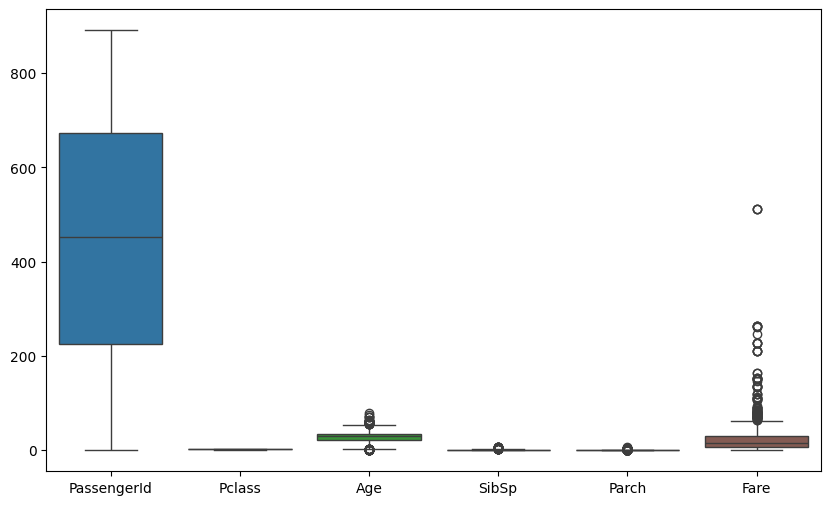

In [111]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=x_train.select_dtypes(include=['int64', 'float64']))
plt.show()

Remplacez les valeurs aberrantes par la médiane de la variable.

In [112]:

n_cols = x_train.select_dtypes(include=['int64', 'float64']).columns

for col in n_cols:

    Q1 = x_train[col].quantile(0.25)
    Q3 = x_train[col].quantile(0.75)
    IQR = Q3 - Q1

    inf = Q1 - 1.5 * IQR
    sup = Q3 + 1.5 * IQR

    median_v = x_train[col].median()

    x_train.loc[(x_train[col] < inf) | (x_train[col] > sup), col] = median_v

    x_test.loc[(x_test[col] < inf) | (x_test[col] > sup), col] = median_v

/tmp/ipykernel_1979/3491422608.py:14: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '453.5' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  x_train.loc[(x_train[col] < inf) | (x_train[col] > sup), col] = median_v
/tmp/ipykernel_1979/3491422608.py:16: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '453.5' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  x_test.loc[(x_test[col] < inf) | (x_test[col] > sup), col] = median_v


**Partie 3 :**

**1. Encodage des variables catégorielles :**


 les colonnes avec des données catégorielles

In [113]:
categor = x_train.select_dtypes(include=['object', 'category']).columns
print("catégorielles :", categor)

catégorielles : Index(['Name', 'Sex', 'Ticket', 'Embarked'], dtype='object')


l'encodage one-hot pour les variables nominales 'Embarked'

In [114]:
x_train_encod = pd.get_dummies(x_train, columns=['Embarked'], drop_first=True)
x_test_encod = pd.get_dummies(x_test, columns=['Embarked'], drop_first=True)

x_train_encod, x_test_encod = x_train_encod.align(x_test_encod, join='left', axis=1, fill_value=0)

Pour les variables ordinales ' class '

 Pclass est souvent déjà sous forme numérique 1, 2, 3

**2. Normalisation et Standardisation des données :**


In [115]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler


Normalisation (Min-Max scaling)

In [116]:
minmax_scaler = MinMaxScaler()
x_train_minmax = x_train.copy()
x_test_minmax = x_test.copy()
x_train_minmax[n_cols] = minmax_scaler.fit_transform(x_train[n_cols])
x_test_minmax[n_cols] = minmax_scaler.transform(x_test[n_cols])

Standardisation (Z-score)

In [117]:
standard_scaler = StandardScaler()
x_train_std = x_train.copy()
x_test_std = x_test.copy()
x_train_std[n_cols] = standard_scaler.fit_transform(x_train[n_cols])
x_test_std[n_cols] = standard_scaler.transform(x_test[n_cols])

Comparaison avant et aprés

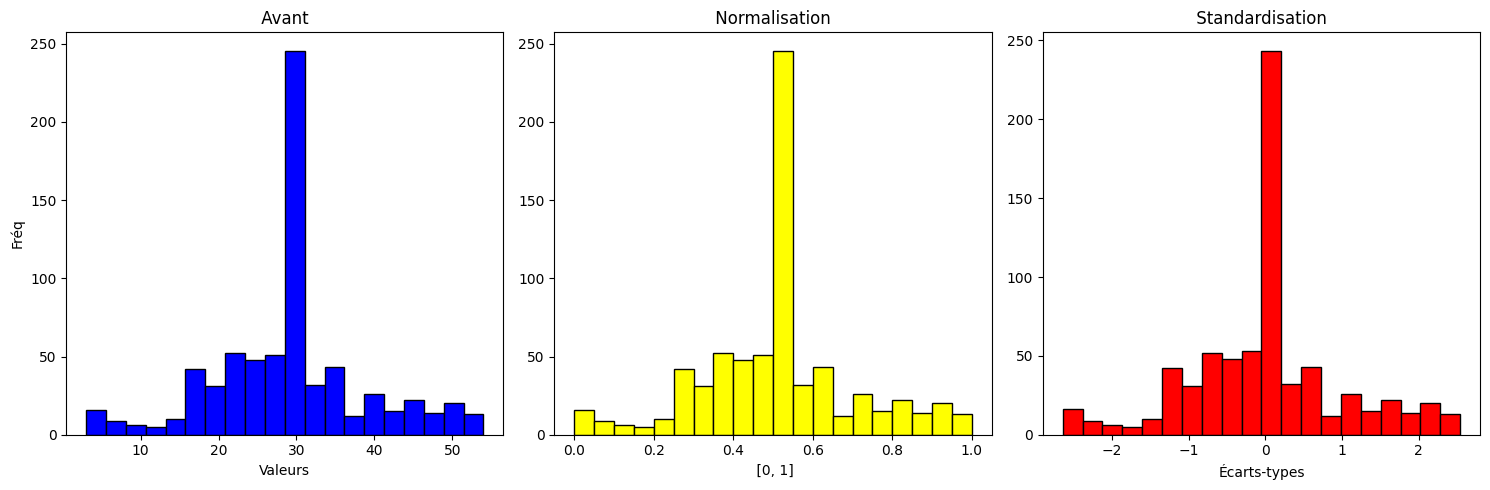

In [118]:
# Choisir une colonne numérique à visualiser (ex: 'Age')
col_to_plot = 'Age'

plt.figure(figsize=(15, 5))

# Avant
plt.subplot(1, 3, 1)
plt.hist(x_train[col_to_plot].dropna(), bins=20, color='blue', edgecolor='black')
plt.title(' Avant ')
plt.xlabel("Valeurs")
plt.ylabel("Fréq")

# Après Normalisation
plt.subplot(1, 3, 2)
plt.hist(x_train_minmax[col_to_plot].dropna(), bins=20, color='yellow', edgecolor='black')
plt.title(' Normalisation ')
plt.xlabel(" [0, 1]")

#  Après Standardisation
plt.subplot(1, 3, 3)
plt.hist(x_train_std[col_to_plot].dropna(), bins=20, color='red', edgecolor='black')
plt.title(' Standardisation ')
plt.xlabel("Écarts-types")

plt.tight_layout()
plt.show()

**Gestion des Données Déséquilibrées**

Identification du déséquilibre des classes

In [119]:
print(y_train.value_counts())
print(y_train.value_counts(normalize=True) * 100)

Survived
0    444
1    268
Name: count, dtype: int64
Survived
0    62.359551
1    37.640449
Name: proportion, dtype: float64


**Gestion du déséquilibre :**

In [120]:
from imblearn.over_sampling import SMOTE

In [128]:
x_train_clean = x_train.select_dtypes(include=['number'])

# Applique SMOTE
smote = SMOTE(random_state=42)
x_train_resampled, y_train_resampled = smote.fit_resample(x_train_clean, y_train)

print("après SMOTE :\n", y_train_resampled.value_counts())

après SMOTE :
 Survived
0    444
1    444
Name: count, dtype: int64
